# Filtering links and chromosomes

After links receive colours, the program can reduce what is drawn. There are three separate settings:

- `min_links` removes chromosomes with too few coloured links
- `max_links` limits all ribbons or only grey ribbons, depending on `max_links_mode`
- `min_chr_size`ment to remove chromosomes and scaffolds shorter than the chosen size, mainly for assemblies with unplaced scafolds 

Here we look at each setting.

## 1. Imports

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import to_rgba
from matplotlib.patches import Rectangle

import functions

## 2. example

Species A is focal. The lower species B has four chromosomes:

- B1 has 1 coloured link
- B2 has 2 coloured links
- B3 has 3 coloured links
- B4 has no links

In [2]:
chain = ["A", "B"]
focal = "A"
default_color = "#e3e3e3"

order = {
    "A": ["A1", "A2"],
    "B": ["B1", "B2", "B3", "B4"],
}

links = pd.DataFrame({
    "chr1": ["A1", "A1", "A1", "A1", "A1", "A1"],
    "gene1": ["A_gene1", "A_gene2", "A_gene3", "A_gene4", "A_gene5", "A_gene6"],
    "pos1": [100, 200, 300, 400, 500, 600],
    "chr2": ["B1", "B2", "B2", "B3", "B3", "B3"],
    "gene2": ["B_gene1", "B_gene2", "B_gene3", "B_gene4", "B_gene5", "B_gene6"],
    "pos2": [100, 200, 300, 400, 500, 600],
    "color": ["#ff0000", "#ff0000", "#ff0000", "#ff0000", "#ff0000", "#ff0000"],
})

links

,chr1,gene1,pos1,chr2,gene2,pos2,color
0,A1,A_gene1,100,B1,B_gene1,100,#ff0000
1,A1,A_gene2,200,B2,B_gene2,200,#ff0000
2,A1,A_gene3,300,B2,B_gene3,300,#ff0000
3,A1,A_gene4,400,B3,B_gene4,400,#ff0000
4,A1,A_gene5,500,B3,B_gene5,500,#ff0000
5,A1,A_gene6,600,B3,B_gene6,600,#ff0000


## 3. Count links with the colour

`min_links` counts only coloured links. Grey links do not count

In [3]:
count = {}
for species in chain:
    count[species] = {}

for chromosome_a, chromosome_b, color in zip(links["chr1"], links["chr2"], links["color"]):
    if color != default_color:
        old_count = count["A"].get(chromosome_a, 0)
        count["A"][chromosome_a] = old_count + 1

        old_count = count["B"].get(chromosome_b, 0)
        count["B"][chromosome_b] = old_count + 1

count_table = []
for species in chain:
    for chromosome in order[species]:
        count_table.append({
            "species": species,
            "chromosome": chromosome,
            "coloured links": count[species].get(chromosome, 0),
        })

pd.DataFrame(count_table)

,species,chromosome,coloured links
0,A,A1,6
1,A,A2,0
2,B,B1,1
3,B,B2,2
4,B,B3,3
5,B,B4,0


## 4. `filter_chromosomes()`

This is the existing function. It repeats the counting above and keeps chromosomes that have at least `min_links` coloured links. The focal species is always kept.

In [4]:
def filter_chromosomes(chain, focal, order, links_by_pair, default_color, min_links):
    count = {}
    for species in chain:
        count[species] = {}

    for pair, pair_links in links_by_pair.items():
        species_a, species_b = pair
        for chromosome_a, chromosome_b, color in zip(pair_links["chr1"], pair_links["chr2"], pair_links["color"]):
            if color != default_color:
                # This coloured link adds one to both chromosomes.
                old_count = count[species_a].get(chromosome_a, 0)
                count[species_a][chromosome_a] = old_count + 1

                old_count = count[species_b].get(chromosome_b, 0)
                count[species_b][chromosome_b] = old_count + 1

    kept = {}

    for species in chain:
        if species == focal:
            kept[species] = list(order[species])
        else:
            kept[species] = []

            for chromosome in order[species]:
                number_of_links = count[species].get(chromosome, 0)

                if number_of_links >= min_links:
                    kept[species].append(chromosome)

    return kept

In [5]:
links_by_pair = {
    ("A", "B"): links
}

min_zero = filter_chromosomes(chain, focal, order, links_by_pair, default_color, 0)
min_one = filter_chromosomes(chain, focal, order, links_by_pair, default_color, 1)
min_three = filter_chromosomes(chain, focal, order, links_by_pair, default_color, 3)

comparison = pd.DataFrame({
    "min_links": [0, 1, 3],
    "focal chromosomes kept": [str(min_zero["A"]), str(min_one["A"]), str(min_three["A"])],
    "lower chromosomes kept": [str(min_zero["B"]), str(min_one["B"]), str(min_three["B"])],
})

comparison

,min_links,focal chromosomes kept,lower chromosomes kept
0,0,"['A1', 'A2']","['B1', 'B2', 'B3', 'B4']"
1,1,"['A1', 'A2']","['B1', 'B2', 'B3']"
2,3,"['A1', 'A2']",['B3']


The result is:

- `min_links = 0`: B1, B2, B3 and B4 stay
- `min_links = 1`: B1, B2 and B3 stay
- `min_links = 3`: only B3 stays

A1 and A2 always stay because A is focal.

## 5. Plot one focal chromosome and its connections

To plot only A1 from the focal species, set `focal_chrs = ["A1"]`. Setting `min_links = 1` then removes chromosomes in the other species that have no coloured connection to A1.

In [6]:
focal_chrs = ["A1"]

selected_order = {
    "A": ["A1"],
    "B": list(order["B"]),
}

chr1_result = filter_chromosomes(chain, focal, selected_order, links_by_pair, default_color, 1)
chr1_result

{'A': ['A1'], 'B': ['B1', 'B2', 'B3']}

A1 is the only focal chromosome kept. B1, B2 and B3 remain because they have coloured links to A1. B4 is removed because it has no such link. There is no automatic change to `min_links`.

## 6. See the filtering in the ribbon plot

Now that the counting is clear we can draw results. As in `drawing_studies.ipynb`, `foot()` places each link at its real position. The small `draw()` function below calls `main_ribbon_painter()` from the main plotting function.

The chromosome positions is staying fixed between panels, so missing Chr leaves a visible gap.

In [62]:
top_left = {"A1": 0.05, "A2": 0.73}
top_width = {"A1": 0.55, "A2": 0.22}
bottom_left = {"B1": 0.04, "B2": 0.28, "B3": 0.52, "B4": 0.76}
bottom_width = {"B1": 0.18, "B2": 0.18, "B3": 0.18, "B4": 0.18}
chromosome_sizes = {"A1": 1000, "A2": 1000, "B1": 1000, "B2": 1000, "B3": 1000, "B4": 1000}
coloured_link_count = {"B1": 1, "B2": 2, "B3": 3, "B4": 0}

def foot(chromosome, position, left, width):
    center = left[chromosome] + position / chromosome_sizes[chromosome] * width[chromosome]
    return (center - 0.006, center + 0.006)

def draw(chromosomes_to_draw, links_to_draw, title):
    figure, axis = plt.subplots(figsize=(8, 2.6))

    for chromosome_a, position_a, chromosome_b, position_b, color in zip(
        links_to_draw["chr1"],
        links_to_draw["pos1"],
        links_to_draw["chr2"],
        links_to_draw["pos2"],
        links_to_draw["color"],
    ):
        if chromosome_a in chromosomes_to_draw["A"] and chromosome_b in chromosomes_to_draw["B"]:
            ribbon = functions.main_ribbon_painter(
                foot(chromosome_a, position_a, top_left, top_width),
                foot(chromosome_b, position_b, bottom_left, bottom_width),
                1.0,
                0.28,
                to_rgba(color, 0.45),
            )
            axis.add_patch(ribbon)

    for chromosome in chromosomes_to_draw["A"]:
        left = top_left[chromosome]
        width = top_width[chromosome]
        axis.add_patch(Rectangle((left, 1.0), width, 0.08, facecolor="#6b7280"))
        axis.text(left + width / 2, 1.14, chromosome, ha="center")

    for chromosome in chromosomes_to_draw["B"]:
        left = bottom_left[chromosome]
        width = bottom_width[chromosome]
        axis.add_patch(Rectangle((left, 0.20), width, 0.08, facecolor="#6b7280"))
        label = f"{chromosome}\n{coloured_link_count[chromosome]} coloured links"
        axis.text(left + width / 2, 0.11, label, ha="center", va="top")

    axis.set_title(title, loc="left")
    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1.28)
    axis.axis("off")
    return figure

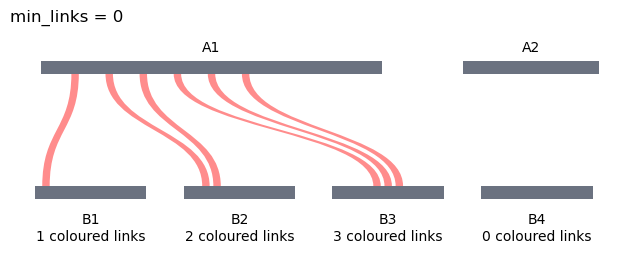

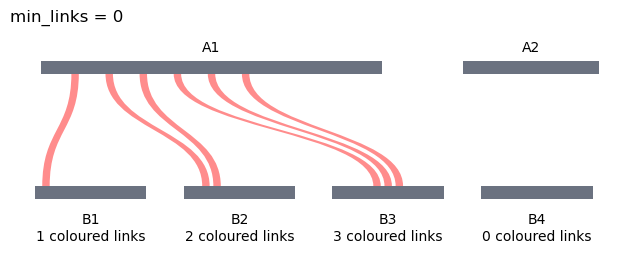

In [8]:
draw(min_zero, links, "min_links = 0")

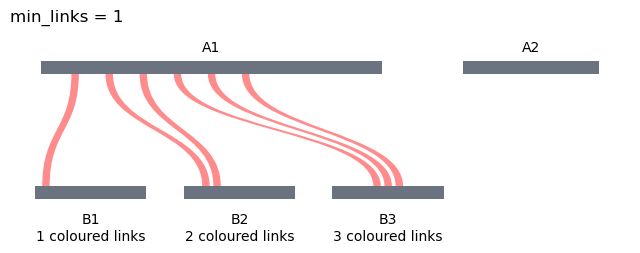

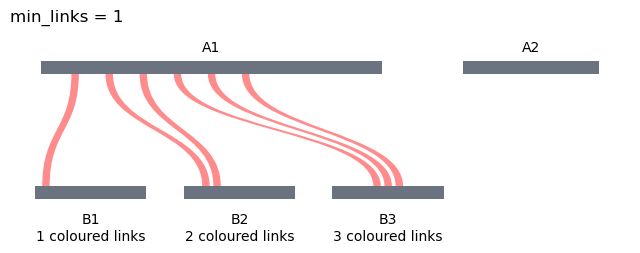

In [9]:
draw(min_one, links, "min_links = 1")

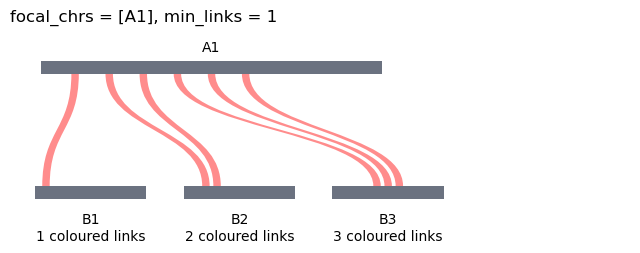

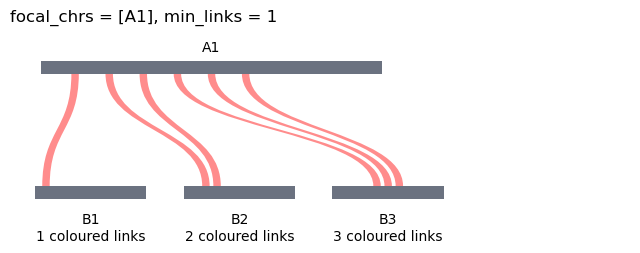

In [10]:
draw(chr1_result, links, "focal_chrs = [A1], min_links = 1")

## 7. `sample_links()` and `max_links`

`max_links_mode` decides which links the maximum applies to:

- `all` caps all links and may remove highlighted (hence important) links
- `grey` caps only grey links and keeps every highlighted link 

In [11]:
def sample_links(links, max_links, default_color, max_links_mode):
    if max_links_mode == "all":
        if len(links) > max_links:
            links = links.sample(n=max_links, random_state=42)
        return links

    colored = links[links["color"] != default_color]
    grey = links[links["color"] == default_color]

    if len(grey) > max_links:
        grey = grey.sample(n=max_links, random_state=42)

    return pd.concat([grey, colored])

In [12]:
grey_links = pd.DataFrame({
    "chr1": ["C1", "C1", "C1", "C1", "C1"],
    "gene1": ["C_gene1", "C_gene2", "C_gene3", "C_gene4", "C_gene5"],
    "pos1": [100, 200, 300, 400, 500],
    "chr2": ["D1", "D1", "D1", "D1", "D1"],
    "gene2": ["D_gene1", "D_gene2", "D_gene3", "D_gene4", "D_gene5"],
    "pos2": [100, 200, 300, 400, 500],
    "color": [default_color, default_color, default_color, default_color, default_color],
})

sampling_links = pd.concat([links, grey_links], ignore_index=True)
sampling_links

,chr1,gene1,pos1,chr2,gene2,pos2,color
0,A1,A_gene1,100,B1,B_gene1,100,#ff0000
1,A1,A_gene2,200,B2,B_gene2,200,#ff0000
2,A1,A_gene3,300,B2,B_gene3,300,#ff0000
3,A1,A_gene4,400,B3,B_gene4,400,#ff0000
4,A1,A_gene5,500,B3,B_gene5,500,#ff0000
5,A1,A_gene6,600,B3,B_gene6,600,#ff0000
6,C1,C_gene1,100,D1,D_gene1,100,#e3e3e3
7,C1,C_gene2,200,D1,D_gene2,200,#e3e3e3
8,C1,C_gene3,300,D1,D_gene3,300,#e3e3e3
9,C1,C_gene4,400,D1,D_gene4,400,#e3e3e3


Now apply the same `max_links = 4` with each mode.

In [13]:
all_mode_links = sample_links(sampling_links, 4, default_color, "all")
grey_mode_links = sample_links(sampling_links, 4, default_color, "grey")

number_colored = len(sampling_links[sampling_links["color"] != default_color])
number_grey = len(sampling_links[sampling_links["color"] == default_color])

mode_comparison = pd.DataFrame({
    "max_links_mode": ["all", "grey"],
    "coloured links in input": [number_colored, number_colored],
    "grey links in input": [number_grey, number_grey],
    "links returned": [len(all_mode_links), len(grey_mode_links)],
})

mode_comparison

,max_links_mode,coloured links in input,grey links in input,links returned
0,all,6,5,4
1,grey,6,5,10


With `all`, only 4 links are returned. With `grey`, 4 grey links and all 6 coloured links are returned, giving 10 links in total.

## 8. Filter chromosomes before sampling ribbons

Chromosome filtering must count the complete coloured links first. Sampling is done afterwards and only changes how many ribbons are drawn.

In [14]:
order_for_plot = filter_chromosomes(chain, focal, order, links_by_pair, default_color, 1)

links_for_plot = {}
for pair, pair_links in links_by_pair.items():
    links_for_plot[pair] = sample_links(pair_links, 2, default_color, "all")

print("chromosomes kept:", order_for_plot)
print("ribbons drawn:", len(links_for_plot[("A", "B")]))

chromosomes kept: {'A': ['A1', 'A2'], 'B': ['B1', 'B2', 'B3']}
ribbons drawn: 2


## 9. Remove small scaffolds with `min_chr_size`

`min_chr_size` is a size in base pairs. Chromosomes and scaffolds below that size are removed. A value of 0 keeps everything.

In [15]:
order_with_scaffolds = {
    "A": ["A1", "A2", "A_scaffold"],
    "B": ["B1", "B2", "B3", "B_scaffold"],
}

sizes_with_scaffolds = {
    "A": {"A1": 1000, "A2": 800, "A_scaffold": 50},
    "B": {"B1": 900, "B2": 700, "B3": 500, "B_scaffold": 40},
}

size_table = []
for species in chain:
    for chromosome in order_with_scaffolds[species]:
        size_table.append({
            "species": species,
            "chromosome": chromosome,
            "size": sizes_with_scaffolds[species][chromosome],
        })

pd.DataFrame(size_table)

,species,chromosome,size
0,A,A1,1000
1,A,A2,800
2,A,A_scaffold,50
3,B,B1,900
4,B,B2,700
5,B,B3,500
6,B,B_scaffold,40


In [16]:
min_chr_size = 200
order_after_size_filter = {}

for species in chain:
    order_after_size_filter[species] = []

    for chromosome in order_with_scaffolds[species]:
        chromosome_size = sizes_with_scaffolds[species][chromosome]

        if chromosome_size >= min_chr_size:
            order_after_size_filter[species].append(chromosome)

In [17]:
order_after_size_filter

{'A': ['A1', 'A2'], 'B': ['B1', 'B2', 'B3']}

Both small scaffolds are removed. The real chromosomes keep their existing plotting order.